In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler

# PARAMETRI

In [2]:
EPOCHS = 100
BATCH_SIZE = 1
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


DATI:
        Month  Passengers
0 1949-01-01         112
1 1949-02-01         118
2 1949-03-01         132
3 1949-04-01         129
4 1949-05-01         121 

LUNGHEZZA DELLA SEQUENZA: (144, 1)

SHAPE: X_TRAIN = (115, 12, 1), Y_TRAIN = (115, 1)
SHAPE: X_TEST = (17, 12, 1), Y_TEST = (17, 1)


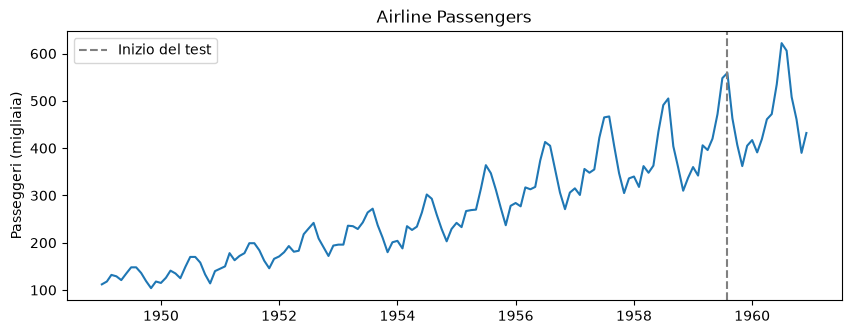

In [3]:
from datasets.datasets import load_AIRLINE
df = load_AIRLINE()
print("DATI:\n", df.head(), "\n")

# DATASET: numero mensile di passeggeri (1949-1960), scalato in [0, 1]
LOOK_BACK = 12        # mesi usati per prevedere il successivo
TRAIN_SPLIT = 0.8

scaler = MinMaxScaler(feature_range=(0, 1))
series = scaler.fit_transform(df[['Passengers']].to_numpy(dtype=np.float32)).astype(np.float32)   # (N, 1)
print(f"LUNGHEZZA DELLA SEQUENZA: {series.shape}\n")

# Esempi supervisionati: LOOK_BACK mesi consecutivi -> mese successivo
x = np.array([series[i:i + LOOK_BACK, 0] for i in range(len(series) - LOOK_BACK)])
y = series[LOOK_BACK:]                       # (esempi, 1)
x = x[:, :, None]                            # (esempi, time steps = LOOK_BACK, features = 1)

# Split temporale: i primi esempi per il training, gli ultimi per il test
train_size = int(len(series) * TRAIN_SPLIT)
train_dataset = TensorDataset(torch.tensor(x[:train_size], dtype=torch.float32), torch.tensor(y[:train_size], dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(x[train_size:], dtype=torch.float32), torch.tensor(y[train_size:], dtype=torch.float32))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"SHAPE: X_TRAIN = {tuple(train_dataset.tensors[0].shape)}, Y_TRAIN = {tuple(train_dataset.tensors[1].shape)}")
print(f"SHAPE: X_TEST = {tuple(test_dataset.tensors[0].shape)}, Y_TEST = {tuple(test_dataset.tensors[1].shape)}")

plt.figure(figsize=(10, 3.5))
plt.plot(df['Month'], df['Passengers'])
plt.axvline(df['Month'][LOOK_BACK + train_size], color='gray', linestyle='--', label='Inizio del test')
plt.title('Airline Passengers')
plt.ylabel('Passeggeri (migliaia)')
plt.legend(loc='upper left')
plt.show()

# MODELLO

In [4]:
#Parametri del modello
INPUT_SIZE = 1
HIDDEN_SIZE = 4
DROPOUT = 0.2

In [5]:
# nn.RNN restituisce (output, (h, c)), quindi non si può mettere direttamente in un nn.Sequential
class RNNForecaster(nn.Module):
    def __init__(self, input_size, hidden_size, dropout=0.0):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):                          # (B, 1, LOOK_BACK)
        out, _ = self.rnn(x)                       # (B, 1, HIDDEN_SIZE)
        return self.fc(out[:, -1])                 # uscita dell'ultimo passo -> (B, 1)

torch.manual_seed(7)
model = RNNForecaster(INPUT_SIZE, HIDDEN_SIZE).to(DEVICE)

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, eps=1e-7)
criterion = nn.MSELoss()

print(model)

RNNForecaster(
  (rnn): RNN(1, 4, batch_first=True)
  (fc): Linear(in_features=4, out_features=1, bias=True)
)


# ADDESTRAMENTO

  0%|          | 0/100 [00:00<?, ?it/s]

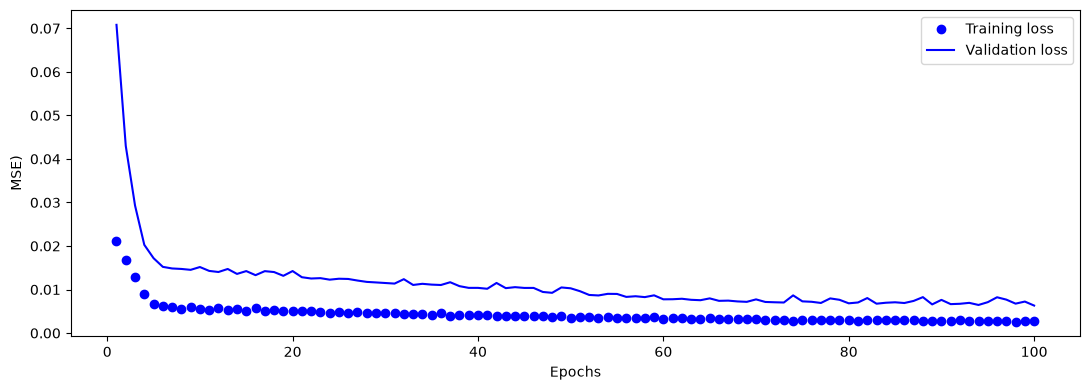

In [6]:
os.makedirs('histories', exist_ok=True)
filename = "timeseries_forecasting"

hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'
if os.path.isfile(hist_path) and os.path.isfile(weights_path):
    with open(hist_path, 'rb') as hist_file:
        history = pickle.load(hist_file)
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
else:
    history = utils.train(model, optimizer, criterion, train_loader, test_loader, EPOCHS, DEVICE)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history, hist_file)
    torch.save(model.state_dict(), weights_path)


plt.figure(figsize=(11, 4))

history
epochs = range(1, len(history['loss']) + 1)
plt.plot(epochs, history['loss'], 'bo', label='Training loss')
plt.plot(epochs, history['val_loss'], 'b', label='Validation loss')
plt.xlabel('Epochs')
plt.ylabel('MSE)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# VALUTAZIONE

In [7]:
# PREVISIONI, riportate nella scala originale (migliaia di passeggeri)
def predict(model, dataset):
    model.eval()
    x, _ = dataset.tensors
    with torch.no_grad():
        return scaler.inverse_transform(model(x.to(DEVICE)).cpu().numpy())

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

y_train_true = scaler.inverse_transform(train_dataset.tensors[1].numpy())
y_test_true = scaler.inverse_transform(test_dataset.tensors[1].numpy())


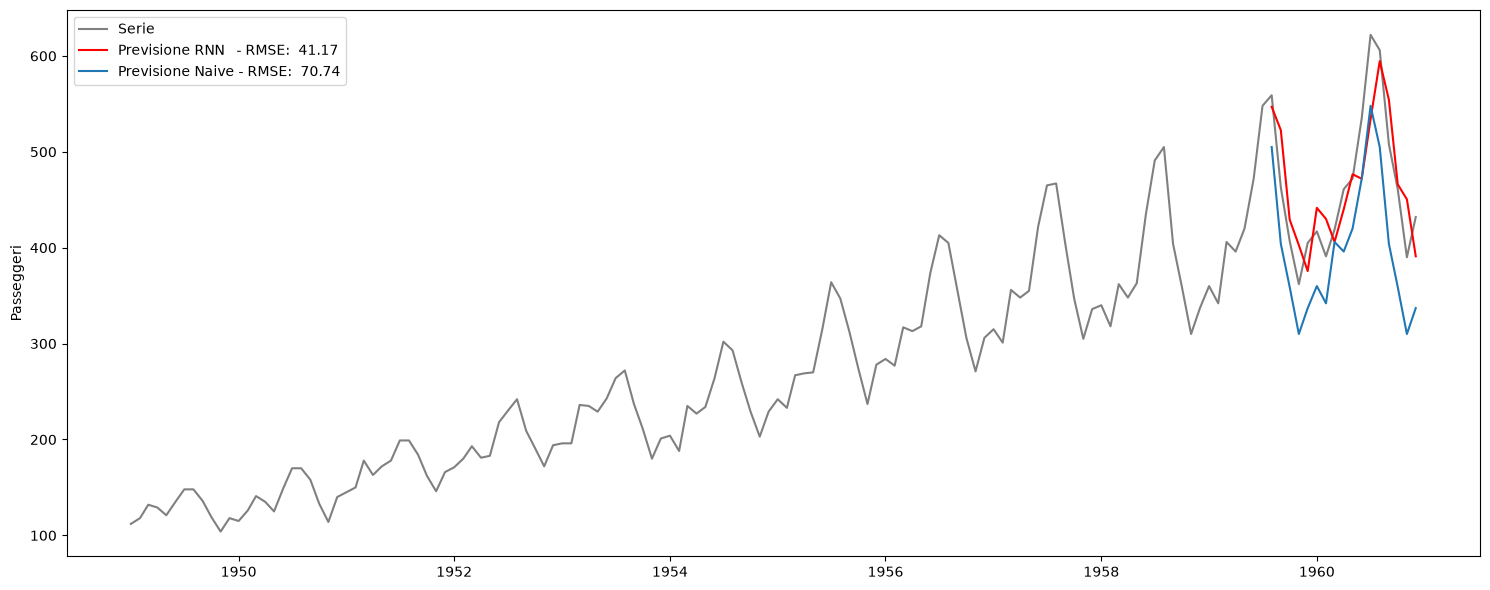

In [8]:
months = df['Month']
train_months = months[LOOK_BACK:LOOK_BACK + train_size]
test_months = months[LOOK_BACK + train_size:]

plt.figure(figsize=(15, 6))
plt.plot(months, df['Passengers'], color='gray', label='Serie')
plt.plot(test_months, predict(model, test_dataset), label=f'Previsione RNN   - RMSE: {rmse(y_test_true, predict(model, test_dataset)):6.2f}', color="red")
plt.plot(test_months, np.resize(y_train_true[-LOOK_BACK:], y_test_true.shape), label=f'Previsione Naive - RMSE: {rmse(y_test_true, np.resize(y_train_true[-LOOK_BACK:], y_test_true.shape)):6.2f}')
plt.ylabel('Passeggeri')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()